# Maze spatial structure: mEC, LEC and PFC through one pipeline

Reads merged tables and shards of one `run_spatial.py --engine maze` run per dataset; it never opens a
data_dic (`RUN_MODE = 'load'`). Write-up: `MAZE_SPATIAL.md`. Galleries of every unit:
`<root>/data/spatial/maze/<tag>/figures/gallery_<recday>.pdf`. The field-shuffle null is the bar for
generalisation claims (2026-10-12).

In [1]:
import os, sys
import numpy as np, pandas as pd
sys.path.insert(0, os.path.abspath('.'))
import maze_spatial_report as r
import spatial_plots as sp
RUN_MODE = 'load'
TAG = 'b705159d8440'
runs = {d: r.load(d, TAG) for d in r.ROOTS}
{d: (run['stamp'].get('cfg_hash', '')[:10], len(run['recdays']), len(run['units'])) for d, run in runs.items()}

{'mec': ('b70515e621', 12, 251),
 'lec': ('b70515e621', 25, 2851),
 'pfc': ('b70515e621', 24, 1229)}

## PFC thesis recipe against the thesis targets (t across recdays, and across mice)

In [2]:
r.thesis_reproduction(runs['pfc']['population']).round(3)

,statistic,chance,thesis_t,mean,t_recdays,p_recdays,n_recdays,t_mice,p_mice,n_mice
0,RSA Euclidean beta,0.000,5.45,1.825,5.107,0.000,24,3.060,0.022,7
1,RSA node-degree beta,0.000,3.51,1.921,3.747,0.001,24,2.160,0.074,7
2,corner/cardinal BA,0.500,3.36,0.581,3.074,0.005,24,1.322,0.234,7
3,node/bridge BA,0.500,4.63,0.626,5.346,0.000,24,2.640,0.039,7
4,same-type error share,0.429,4.32,0.536,4.561,0.000,24,2.243,0.066,7


In [3]:
r.thesis_planes('pfc', TAG).round(1)

,bin_distance,mean_deg,sem_deg,n_recdays
0,0,8.6,0.7,24
1,1,51.8,3.5,24
2,2,63.0,4.2,24
3,3,65.3,4.1,24
4,4,64.6,4.7,24


## Decided recipe, mouse level: mice with p <= 0.05 against the mean-over-recdays null (field shuffle is the bar)

In [4]:
pd.concat([r.mouse_claims(d, run) for d, run in runs.items()])

,dataset,statistic,null,n_mice,hits,p_binomial,p_signflip,mice,min_n_sims,range
0,mec,"RSA node-degree beta, E+D, 9 nodes",place_shuffled,2,0,1.000000e+00,NaN,,200,0.07 to 0.16
1,mec,"RSA node-degree beta, E+D, 9 nodes",speed,2,0,1.000000e+00,NaN,,200,0.07 to 0.16
2,mec,"RSA node-degree beta, E+D, 9 nodes",place,2,2,2.500000e-03,NaN,"bp01,bp04",200,0.07 to 0.16
3,mec,"RSA node-degree beta, E+D, 9 nodes",place_random,2,0,1.000000e+00,NaN,,200,0.07 to 0.16
4,mec,"RSA node-degree beta, E+D, 9 nodes",boundary,2,0,1.000000e+00,NaN,,200,0.07 to 0.16
...,...,...,...,...,...,...,...,...,...,...
25,pfc,"RSA node/bridge beta, E+NB, 21 locations",place_shuffled,7,7,7.812500e-10,0.007812,"ab03,ah03,ah04,ah07,me08,me10,me11",200,0.11 to 0.65
26,pfc,"RSA node/bridge beta, E+NB, 21 locations",speed,7,5,6.027344e-06,0.023438,"ah03,ah04,me08,me10,me11",200,0.11 to 0.65
27,pfc,"RSA node/bridge beta, E+NB, 21 locations",place,7,7,7.812500e-10,0.007812,"ab03,ah03,ah04,ah07,me08,me10,me11",200,0.11 to 0.65
28,pfc,"RSA node/bridge beta, E+NB, 21 locations",place_random,7,7,7.812500e-10,0.007812,"ab03,ah03,ah04,ah07,me08,me10,me11",200,0.11 to 0.65


## Per mouse: real value against the field-shuffle null (mean to p95)

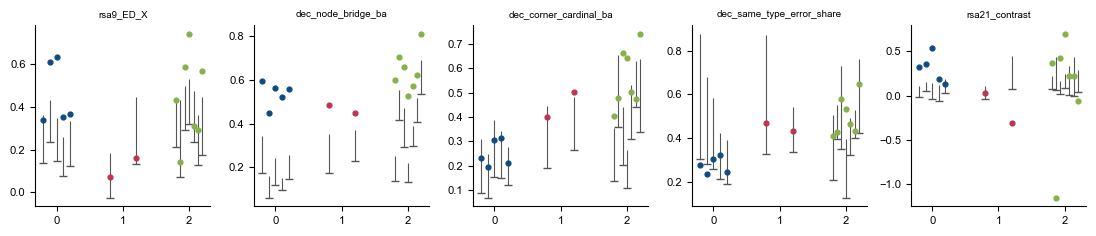

In [5]:
pop = pd.concat([run['population'].assign(dataset=d) for d, run in runs.items()])
nl = pd.concat([run['nulls'].assign(dataset=d) for d, run in runs.items()])
nl = nl[~((nl.dataset == 'mec') & (nl.mouse == 'bp02'))]
fig = sp.plot_population_vs_null(pop, nl, ['rsa9_ED_X', 'dec_node_bridge_ba', 'dec_corner_cardinal_ba',
                                           'dec_same_type_error_share', 'rsa21_contrast'], null_kind='place_shuffled')

## Plane angles (k = 3): across goal-progress bins against the halves and tasks controls

In [6]:
cols = ['planes_k3_halves_max', 'planes_k3_tasks_max', 'planes_k3_across_max']
pd.concat({d: run['population'][run['population'].recipe == 'decided'].groupby('mouse')[cols].mean()
           for d, run in runs.items()}).round(1)

planes_k3_halves_max  planes_k3_tasks_max  planes_k3_across_max
    mouse                                                                 
mec bp01                   31.6                 65.4                  50.8
    bp02                   25.7                 36.7                  33.8
    bp04                   32.4                 70.9                  55.1
lec ah08                   39.9                 67.3                  58.9
    ah10                   20.4                 49.5                  42.2
    ly05                   33.8                 61.7                  47.3
    ly06                   27.9                 57.0                  46.6
    ly07                   33.1                 59.3                  57.7
pfc ab03                   30.3                 60.4                  45.4
    ah03                   62.6                 78.8                  82.3
    ah04                   55.1                 82.3                  76.8
    ah07                   40.0                 71.6                  61.5
    me08                   39.5                 68.9                  62.8
    me10                   37.7                 54.5                  55.2
    me11                   53.9                 80.0                  77.4

## Single units per mouse

In [7]:
def unit_counts(u):
    g = u.groupby('mouse')
    return pd.DataFrame({'units': g.size(), 'stable': g.stable.sum(),
                         **{k: g[f'is_{k}'].sum() for k in ('corner', 'cardinal', 'centre', 'node', 'bridge')}})
pd.concat({d: unit_counts(run['units']) for d, run in runs.items()})

units  stable  corner  cardinal  centre  node  bridge
    mouse                                                       
mec bp01     180     180      12         0      11    29       2
    bp02      17      13       1         0       2     2       3
    bp04      54      53       1         4       5     4       0
lec ah08     792     688       9         1      67    32      33
    ah10     772     727      39         2      79    20      15
    ly05     507     414      43         0      17    11      14
    ly06     356     313      20         0      18     1       6
    ly07     424     399      16         0      22    15      17
pfc ab03     197     186       7         2      25    12      18
    ah03      31      20       0         0       1     8       2
    ah04     481     421      23         7      54   112      32
    ah07     249     219      17         4      38    11       5
    me08      55      50      10         0       5     6       3
    me10      55      46       2         0       0    21       5
    me11     161     152      21        10       6    88      25